**Student Name:** Runge Wang
**Student ID:** C00304516

## Table of Contents

1. Introduction
2. Dataset Description
3. Data Loading and Exploration
4. Exploratory Data Analysis
5. Data Preprocessing
6. Model Training and Evaluation
7. Data Leakage Checks
8. Model Comparison
9. Grouped Cross-Validation
10. Conclusion


## 1. Introduction

### 1.1 Project Background

Daily activities such as transportation, electricity consumption, food choices and waste generation can contribute to an individual's carbon footprint.

This project investigates how lifestyle-related variables are associated with daily carbon footprint values using machine learning.

### 1.2 Project Aim

The aim is to predict `carbon_footprint_kg` using daily lifestyle features.

This is a supervised regression task because the target is a continuous numerical value.

### 1.3 Project Objectives

- Explore the dataset and check data quality.
- Prepare categorical and numerical features.
- Train and compare three regression models.
- Evaluate prediction accuracy using MAE, RMSE and R².
- Use group-based validation to avoid sharing users between training and validation data.
- Discuss model performance and limitations.


## 2. Dataset Description

### 2.1 Dataset Source

The dataset is the Personal Carbon Footprint Behavior Dataset, published by Sonal Shinde on Kaggle.

Source:
https://www.kaggle.com/datasets/sonalshinde123/personal-carbon-footprint-behavior-dataset

The dataset is synthetic rather than collected from real individuals.

### 2.2 Dataset Overview

The dataset contains 1,400 records, 200 unique users and 12 columns.

It includes information about transport, electricity consumption, food, screen time, waste generation and environmental actions.

### 2.3 Prediction Target

The target variable is `carbon_footprint_kg`.

The project uses nine lifestyle-related input features.

The `user_id` column is used for group splitting rather than prediction. The `carbon_impact_level` column is excluded because it may be derived from the target.

### 2.4 Limitation

Since the data is synthetic, the results cannot automatically be generalised to real-world carbon footprints.


## 3. Data Loading and Exploration

### 3.1 Loading the Dataset

The dataset is loaded from a CSV file using the Pandas library. Pandas provides tools for organising, inspecting and analysing structured data.

The first step is to examine the dataset's dimensions and sample records. This helps confirm that the file has been loaded correctly and provides an initial understanding of the available variables.

The dataset contains daily lifestyle information and corresponding carbon footprint values, which will be used in the subsequent exploratory analysis and machine learning experiments.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv("personal_carbon_footprint_behavior.csv")
print(df.shape)
df.head()

(1400, 12)


,user_id,day_type,transport_mode,distance_km,electricity_kwh,renewable_usage_pct,food_type,screen_time_hours,waste_generated_kg,eco_actions,carbon_footprint_kg,carbon_impact_level
0,1,Weekend,EV,1.55,6.12,0,Non-Veg,2.4,0.70,1,11.03,High
1,1,Weekend,Walk,10.04,4.50,0,Mixed,4.1,0.54,1,7.44,Medium
2,1,Weekday,Walk,15.27,2.81,0,Mixed,4.0,0.51,1,6.01,Medium
3,1,Weekend,Walk,0.50,10.16,0,Mixed,6.3,0.73,0,12.70,High
4,1,Weekend,Walk,3.60,5.02,50,Mixed,5.1,0.64,0,6.33,Medium


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              1400 non-null   int64  
 1   day_type             1400 non-null   object 
 2   transport_mode       1400 non-null   object 
 3   distance_km          1400 non-null   float64
 4   electricity_kwh      1400 non-null   float64
 5   renewable_usage_pct  1400 non-null   int64  
 6   food_type            1400 non-null   object 
 7   screen_time_hours    1400 non-null   float64
 8   waste_generated_kg   1400 non-null   float64
 9   eco_actions          1400 non-null   int64  
 10  carbon_footprint_kg  1400 non-null   float64
 11  carbon_impact_level  1400 non-null   object 
dtypes: float64(5), int64(3), object(4)
memory usage: 131.4+ KB


In [35]:
print(df.isnull().sum())


user_id                0
day_type               0
transport_mode         0
distance_km            0
electricity_kwh        0
renewable_usage_pct    0
food_type              0
screen_time_hours      0
waste_generated_kg     0
eco_actions            0
carbon_footprint_kg    0
carbon_impact_level    0
dtype: int64


### 3.2 Data Quality Checks

Before building machine learning models, it is important to assess the quality of the dataset.

Missing values may affect model training and data analysis, while duplicate records can influence the distribution of observations.

The following code checks duplicate rows and the number of unique users. The following code checks missing values, duplicate records and the number of unique users.

Understanding the user structure is important for selecting an appropriate training and testing strategy later in the project.


In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique users:", df["user_id"].nunique())

Duplicate rows: 0
Unique users: 200


### 3.3 Data Quality Findings

The duplicate-row check showed that the dataset contains no exact duplicate rows.

The dataset includes 200 unique users across 1,400 observations. Since multiple records belong to the same users, a user-based splitting strategy will be considered during model preparation to reduce the risk of data leakage.

No missing values were found in any of the 12 columns.

### 3.4 Descriptive Statistics

Descriptive statistics are used to understand the numerical features of the dataset.

The `df.describe()` function provides summary statistics, including the count, mean, standard deviation, minimum, maximum and quartile values.

These statistics help identify the typical values, ranges and variability of numerical features before further exploratory data analysis.


In [6]:
df.describe()

,user_id,distance_km,electricity_kwh,renewable_usage_pct,screen_time_hours,waste_generated_kg,eco_actions,carbon_footprint_kg
count,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000
mean,100.500000,9.106071,5.951443,31.589286,5.521786,0.703200,1.144286,7.980236
std,57.754936,4.734692,1.993266,30.598496,2.018918,0.236415,1.019066,2.657858
min,1.000000,0.500000,2.000000,0.000000,2.000000,0.100000,0.000000,1.790000
25%,50.750000,5.662500,4.530000,0.000000,3.800000,0.550000,0.000000,6.080000
50%,100.500000,9.180000,5.925000,25.000000,5.550000,0.705000,1.000000,7.835000
75%,150.250000,12.510000,7.290000,50.000000,7.300000,0.860000,2.000000,9.830000
max,200.000000,22.670000,12.270000,100.000000,9.000000,1.510000,5.000000,16.020000


## 4. Exploratory Data Analysis

### 4.1 Distribution of Carbon Footprint

Exploratory Data Analysis (EDA) is used to understand the patterns and characteristics of the dataset before model training.

In this section, a histogram is used to examine the distribution of `carbon_footprint_kg`, which is the target variable of this project.

The histogram helps visualise the frequency of different carbon footprint values and understand how the target variable varies across observations.


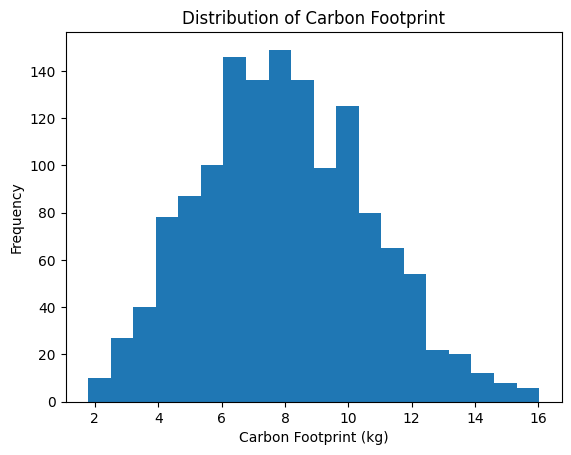

In [7]:
plt.hist(df["carbon_footprint_kg"], bins=20)

plt.xlabel("Carbon Footprint (kg)")
plt.ylabel("Frequency")
plt.title("Distribution of Carbon Footprint")

plt.show()

### 4.2 Distribution Findings

The carbon footprint values range from approximately 1.79 kg to 16.02 kg, with an average of approximately 7.98 kg.

The histogram shows that daily carbon footprint values vary across observations.

This variation makes the dataset suitable for exploring relationships between lifestyle features and the numerical prediction target.


### 4.3 Carbon Footprint by Transport Mode

Transport mode is one of the lifestyle features included in the dataset.

A boxplot is used to compare the distribution of carbon footprint values across different transport categories.

The boxplot displays the median, quartiles and spread of carbon footprint values for each transport mode. This helps identify differences between transport categories and examine their possible association with personal carbon footprint.


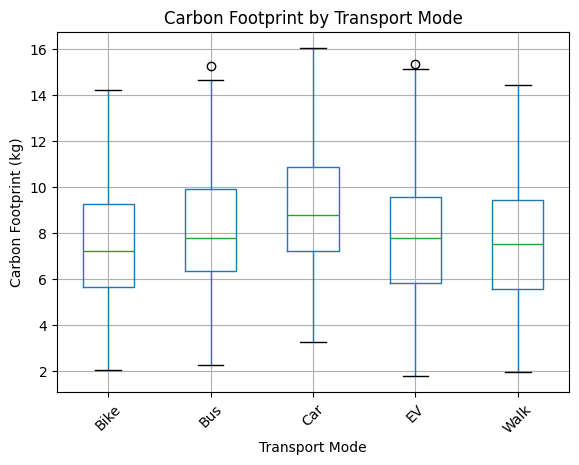

In [8]:
df.boxplot(
    column="carbon_footprint_kg",
    by="transport_mode",
    rot=45
)

plt.title("Carbon Footprint by Transport Mode")
plt.suptitle("")
plt.xlabel("Transport Mode")
plt.ylabel("Carbon Footprint (kg)")

plt.show()


### 4.4 Transport Mode Findings

The boxplot suggests that carbon footprint values differ across transport modes.

Car observations tend to have a higher median carbon footprint than bike observations. However, the distributions overlap, indicating that transport mode alone does not fully explain the differences in carbon footprint values.

These results suggest an association between transport mode and carbon footprint, but they do not establish a causal relationship.



## 5. Data Preprocessing

### 5.1 Feature Selection

Data preprocessing is an important step before training machine learning models. It involves preparing the input features and target variable for prediction.

In this project, `carbon_footprint_kg` is selected as the target variable (`y`), while the remaining lifestyle-related variables are used as input features (`X`).

Three columns are excluded from the input features:

- `user_id`: This is an identifier rather than a lifestyle feature. It will be used later for group-based data splitting.
- `carbon_footprint_kg`: This is the prediction target and must not be included in the input features.
- `carbon_impact_level`: This variable may be derived from the target and could introduce target leakage.

After excluding these columns, nine lifestyle-related features remain for model training.


In [9]:
X = df.drop(columns=[
    "user_id",
    "carbon_footprint_kg",
    "carbon_impact_level"
])

y = df["carbon_footprint_kg"]

print("Features:", X.columns.tolist())
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['day_type', 'transport_mode', 'distance_km', 'electricity_kwh', 'renewable_usage_pct', 'food_type', 'screen_time_hours', 'waste_generated_kg', 'eco_actions']
X shape: (1400, 9)
y shape: (1400,)



### 5.2 Group-Based Train-Test Split

The dataset contains 1,400 observations from 200 unique users. Since each user has multiple records, a standard random train-test split could place observations from the same user in both datasets.

To reduce this risk, `GroupShuffleSplit` is used with `user_id` as the grouping variable.

The dataset is divided into 80% training data and 20% testing data, using `random_state=42` for reproducibility.

This approach ensures that observations from the same user are assigned to either the training set or the testing set, rather than both.

The training set is used to fit the machine learning models, while the testing set is reserved for evaluating their performance on unseen users.



In [31]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_index, test_index = next(
    
    splitter.split(X, y, groups=df["user_id"])
)
print("Training records:", len(train_index))
print("Testing records:", len(test_index))

Training records: 1120
Testing records: 280


In [11]:
X_train = X.iloc[train_index]
X_test = X.iloc[test_index]

y_train = y.iloc[train_index]
y_test = y.iloc[test_index]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1120, 9)
X_test: (280, 9)
y_train: (1120,)
y_test: (280,)


In [12]:
train_users = set(df.iloc[train_index]["user_id"])
test_users = set(df.iloc[test_index]["user_id"])

print("Training users:", len(train_users))
print("Testing users:", len(test_users))

print("No user overlap:", train_users.isdisjoint(test_users))

Training users: 160
Testing users: 40
No user overlap: True


**Missing-value check**

The next cell counts missing values in each column. This check is separate from the user-based train-test split above.



### 5.3 Train-Test Split Findings

The training set contains 1,120 observations from 160 users, while the testing set contains 280 observations from 40 users.

The user overlap check confirms that no users appear in both datasets.

This reduces the risk of data leakage caused by repeated observations from the same individuals.



### 5.4 Categorical Feature Encoding

The dataset contains both numerical and categorical features.

The categorical features include:

- `day_type`
- `transport_mode`
- `food_type`

These variables contain text categories, which cannot be directly used by the selected regression models without suitable preprocessing.

One-Hot Encoding is used to convert each category into numerical indicator features.

In this project, `OneHotEncoder` is combined with `ColumnTransformer` to transform the categorical columns while keeping the remaining numerical columns unchanged.

The `handle_unknown="ignore"` setting allows the encoder to handle categories in the test data that were not observed during training.

The preprocessing is later included inside the machine learning pipelines so that it is fitted using the training data.


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = [
    "day_type",
    "transport_mode",
    "food_type"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ],
    remainder="passthrough"
)

print("Preprocessor created successfully")

Preprocessor created successfully



## 6. Model Training and Evaluation

### 6.1 Linear Regression

Linear Regression is used as the first machine learning model to predict daily personal carbon footprint.

It estimates the relationship between the input lifestyle features and the continuous target variable, `carbon_footprint_kg`.

A Scikit-learn Pipeline is used to combine the preprocessing steps with Linear Regression. This ensures that categorical encoding is applied consistently during model training and prediction.

The model is trained using `X_train` and `y_train`. After training, it is used to predict carbon footprint values for the unseen test set.

The predictions are evaluated using three metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted values.
- **Root Mean Squared Error (RMSE):** Measures prediction error while giving greater weight to larger errors.
- **R² Score:** Indicates how much of the variation in the target is explained by the model.

Lower MAE and RMSE values, together with a higher R² score, generally indicate better prediction performance.


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

print("Model pipeline created")

Model pipeline created


In [15]:
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [19]:
y_pred = model.predict(X_test)

print("First 5 predictions:")
print(y_pred[:5])

First 5 predictions:
[7.23523829 5.45505669 3.642065   7.62428781 9.96636008]


In [20]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head())

   Actual  Predicted
0    6.26   7.235238
1    5.23   5.455057
2    4.35   3.642065
3    7.76   7.624288
4    9.46   9.966360


In [21]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2:", round(r2, 4))

MAE: 0.454
RMSE: 0.6153
R2: 0.9479



### 6.2 Linear Regression Results

The Linear Regression model achieved the following results on the test set:

- MAE: 0.4540 kg
- RMSE: 0.6153 kg
- R²: 0.9479

The MAE indicates that the model's predictions differ from the actual carbon footprint values by approximately 0.4540 kg on average.

The R² score of 0.9479 indicates that the model explains approximately 94.79% of the variation in the test set's carbon footprint values.

These results suggest that Linear Regression performs well on this synthetic dataset.


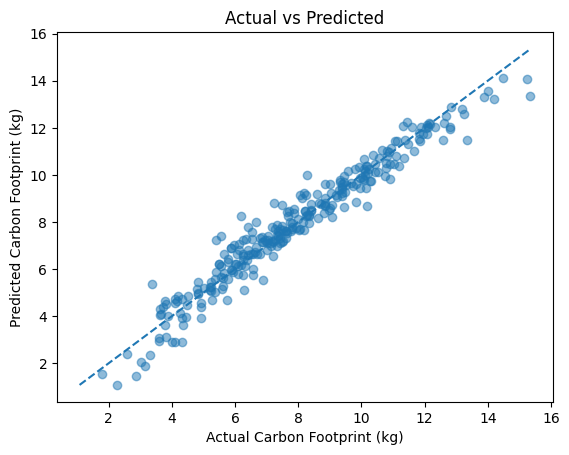

In [22]:
plt.scatter(y_test, y_pred, alpha=0.5)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "--")

plt.xlabel("Actual Carbon Footprint (kg)")
plt.ylabel("Predicted Carbon Footprint (kg)")
plt.title("Actual vs Predicted")

plt.show()


### 6.3 Dummy Regressor (Baseline Model)

A Dummy Regressor is used as a baseline model to provide a simple reference for evaluating the performance of the machine learning models.

In this project, the Dummy Regressor uses the mean strategy, which predicts the average carbon footprint value from the training data for every test observation.

The purpose of this baseline is to determine whether Linear Regression and Random Forest can achieve better prediction accuracy than a simple constant prediction.

The Dummy Regressor is evaluated using the same test set and performance metrics to ensure a fair comparison.


In [16]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_pred)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_pred))
dummy_r2 = r2_score(y_test, dummy_pred)

print("Dummy Regressor Results")
print("MAE:", round(dummy_mae, 4))
print("RMSE:", round(dummy_rmse, 4))
print("R2:", round(dummy_r2, 4))


Dummy Regressor Results
MAE: 2.2161
RMSE: 2.6966
R2: -0.0008



### 6.4 Random Forest Regressor

Random Forest Regressor is used as a second machine learning regression model.

Unlike Linear Regression, Random Forest combines predictions from multiple decision trees and can model more complex, non-linear relationships between input features and the target variable.

In this project, the Random Forest model uses 100 decision trees with `random_state=42` to make the experiment reproducible.

The model uses the same training and testing data as Linear Regression. Categorical preprocessing is included in the Pipeline.

Its predictions are evaluated using MAE, RMSE and R² so that the results can be compared with the other models.

    

In [17]:

from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2:", round(rf_r2, 4))


Random Forest Results
MAE: 0.4943
RMSE: 0.6581
R2: 0.9404


## 7. Model Comparison

The following table compares test-set MAE, RMSE, and R² for Dummy Regressor, Linear Regression, and Random Forest, sorted by MAE.


In [23]:
results = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [dummy_mae, mae, rf_mae],
    "RMSE": [dummy_rmse, rmse, rf_rmse],
    "R2": [dummy_r2, r2, rf_r2]
})

results = results.sort_values("MAE")

print(results.round(4).to_string(index=False))


            Model    MAE   RMSE      R2
Linear Regression 0.4540 0.6153  0.9479
    Random Forest 0.4943 0.6581  0.9404
  Dummy Regressor 2.2161 2.6966 -0.0008


## 8. Grouped Cross-Validation

Five-fold grouped cross-validation is applied to the training data using `user_id` as the grouping variable. The first cell reports mean MAE and R² for each model. The next cell reports MAE for each fold, its mean, and its standard deviation.


In [24]:

from sklearn.model_selection import GroupKFold, cross_validate

train_groups = df.iloc[train_index]["user_id"]

cv = GroupKFold(n_splits=5)

models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "Linear Regression": model,
    "Random Forest": rf_model
}

for name, current_model in models.items():
    scores = cross_validate(
        current_model,
        X_train,
        y_train,
        groups=train_groups,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        }
    )

    mean_mae = -scores["test_MAE"].mean()
    mean_r2 = scores["test_R2"].mean()

    print(name)
    print("Average MAE:", round(mean_mae, 4))
    print("Average R2:", round(mean_r2, 4))
    print()


Dummy
Average MAE: 2.14
Average R2: -0.0023

Linear Regression
Average MAE: 0.4878
Average R2: 0.9384

Random Forest
Average MAE: 0.5077
Average R2: 0.9335



In [25]:
for name, current_model in models.items():
    scores = cross_validate(
        current_model,
        X_train,
        y_train,
        groups=train_groups,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    fold_mae = -scores["test_score"]

    print(name)
    print("MAE for each fold:", np.round(fold_mae, 4))
    print("Mean MAE:", round(fold_mae.mean(), 4))
    print("Standard deviation:", round(fold_mae.std(), 4))
    print()


Dummy
MAE for each fold: [2.1948 2.1098 2.2784 2.0062 2.1105]
Mean MAE: 2.14
Standard deviation: 0.0915

Linear Regression
MAE for each fold: [0.4805 0.4911 0.5131 0.4717 0.4827]
Mean MAE: 0.4878
Standard deviation: 0.0141

Random Forest
MAE for each fold: [0.5096 0.4869 0.5259 0.5103 0.506 ]
Mean MAE: 0.5077
Standard deviation: 0.0125



## 9. Data Leakage Checks

The following cell checks the number of users shared between the training and test sets and confirms that `user_id`, `carbon_footprint_kg`, and `carbon_impact_level` are excluded from the input features. It repeats the user-overlap check from Section 5 and adds explicit feature-exclusion checks. These checks do not rule out every possible source of leakage.


In [18]:
train_users = set(df.iloc[train_index]["user_id"])
test_users = set(df.iloc[test_index]["user_id"])

print("Training users:", len(train_users))
print("Testing users:", len(test_users))
print("Overlapping users:", len(train_users & test_users))

print("Features:", X.columns.tolist())

print("User ID excluded:", "user_id" not in X.columns)
print("Target excluded:", "carbon_footprint_kg" not in X.columns)
print("Impact level excluded:", "carbon_impact_level" not in X.columns)


Training users: 160
Testing users: 40
Overlapping users: 0
Features: ['day_type', 'transport_mode', 'distance_km', 'electricity_kwh', 'renewable_usage_pct', 'food_type', 'screen_time_hours', 'waste_generated_kg', 'eco_actions']
User ID excluded: True
Target excluded: True
Impact level excluded: True


## 10. Conclusion

### 10.1 Model Performance

Three regression models were evaluated to predict daily personal carbon footprint (kg): Dummy Regressor, Linear Regression and Random Forest Regressor.

The dataset was divided into 1,120 training records and 280 testing records using a user-based split.

Linear Regression achieved the lowest test MAE of 0.4540 kg, an RMSE of 0.6153 kg and an R² of 0.9479.

Random Forest achieved an MAE of 0.4943 kg and an R² of 0.9404, while Dummy Regressor had a much higher MAE of 2.2161 kg.

Linear Regression performed best among the three models on the independent test set.


### 10.2 Interpretation of Results

The scatter plot compares actual and predicted carbon footprint values for Linear Regression. Most points are close to the diagonal line, suggesting that the predictions are generally close to the actual values.

Five-fold group-based cross-validation was also performed on the training data.

Linear Regression achieved the lowest average MAE of 0.4878 kg, followed by Random Forest at 0.5077 kg and Dummy Regressor at 2.1400 kg.

Random Forest showed slightly less variation across folds, but Linear Regression achieved a lower average MAE.

The results suggest that a more complex model does not necessarily achieve better predictive performance on this dataset.


### 10.3 Limitations

One limitation is that the dataset is synthetic rather than collected from real-world observations. Although the models achieved high R² values on the test set, their performance may be different when applied to real-world data.

Three regression models were compared, but the experiment did not include extensive hyperparameter tuning or testing on an external dataset.

Although group-based splitting and cross-validation were used to reduce data leakage risks, these methods cannot guarantee that all possible sources of data leakage have been eliminated.

Therefore, the results should be interpreted with caution.


### 10.4 Future Improvements

Future work could investigate which lifestyle features contribute most strongly to carbon footprint predictions.

Hyperparameter tuning could also be applied to Random Forest to investigate whether its predictive performance can be improved.

In addition, if suitable real-world carbon footprint data becomes available, the models could be evaluated on this data to assess their generalisation ability and practical usefulness.


## 11. References

Scikit-learn developers (n.d.) *Cross-validation: Evaluating Estimator Performance*. Scikit-learn User Guide. Available at: https://scikit-learn.org/stable/modules/cross_validation.html (Accessed: 26 October 2026).

Scikit-learn developers (n.d.) *cross_validate*. Scikit-learn Documentation. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html (Accessed: 26 October 2026).

Scikit-learn developers (n.d.) *DummyRegressor*. Scikit-learn Documentation. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html (Accessed: 27 October 2026).

Scikit-learn developers (n.d.) *RandomForestRegressor*. Scikit-learn Documentation. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html (Accessed: 26 October 2026).

Shinde, S. (n.d.) *Personal Carbon Footprint Behavior Dataset*. Kaggle. Available at: https://www.kaggle.com/datasets/sonalshinde123/personal-carbon-footprint-behavior-dataset (Accessed: 7 October 2026).

### Blackboard Lecture Materials

South East Technological University (n.d.) *Data Science Linear Regression*. Data Science and Machine Learning 1 – Y4. Lecture slides. Available at: https://blackboard.itcarlow.ie/ultra/courses/_40126_1/outline (Accessed: 15 October 2026).

## 12. Work Diary

### Week 1: 19–25 October 2026

| Date | Work Completed |
|---|---|
| 25 October 2026 | Project topic selection and dataset selection. |

#### Reflection — Dataset Selection

- Project focus: predicting daily personal carbon footprint from lifestyle-related variables.
- Dataset source: Kaggle Personal Carbon Footprint Behavior Dataset.
- Important finding: the dataset is synthetic rather than collected from real-world participants.
- Learning point: a dataset can be suitable for testing machine learning methods without necessarily representing real-world behaviour.
- I learned that good prediction results on synthetic data do not necessarily mean the model will perform equally well on real-world data.


### Week 2: 26 October – 1 November 2026

| Date | Work Completed |
|---|---|
| 26 October 2026 | Data loading and data quality checks. |
| 27 October 2026 | Exploratory data analysis and data visualisation. |
| 28 October 2026 | Feature selection, data preprocessing, group-based train-test splitting, and model training. |
| 29 October 2026 | Model prediction, performance evaluation, and comparison of regression models. |

#### Reflection — Data Exploration and Preprocessing

- The dataset contains 1,400 records from 200 users.
- No missing values or exact duplicate rows were found.
- The histogram helped examine the distribution of carbon footprint values.
- The transport-mode boxplot showed differences in carbon footprint distributions between transport categories.
- Because individual users have multiple records, randomly splitting rows could place records from the same user in both training and testing.
- `GroupShuffleSplit` was used to separate users between the two sets.
- `carbon_impact_level` was excluded because it could reveal information related to the prediction target.

#### Reflection — Model Comparison

- Three models were compared: Dummy Regressor, Linear Regression and Random Forest.
- Dummy Regressor provided a basic reference point by predicting the training-set mean.
- Test MAE:
  - Dummy Regressor: 2.2161 kg
  - Linear Regression: 0.4540 kg
  - Random Forest: 0.4943 kg
- Linear Regression achieved the lowest test error.
- Learning point: increasing model complexity does not guarantee better predictive performance.
- MAE, RMSE and R² provided different ways to evaluate the models rather than relying on a single score.


### Week 3: 2–8 November 2026

| Date | Work Completed |
|---|---|
| 2 November 2026 | Grouped cross-validation and data leakage checks. |
| 2 November 2026 | Interpretation of model results, conclusion and documentation. |

#### Reflection — Validation and Reliability

- Five-fold `GroupKFold` cross-validation was used to evaluate the models while keeping records from the same user together.
- Average cross-validation MAE:
  - Linear Regression: 0.4878 kg
  - Random Forest: 0.5077 kg
  - Dummy Regressor: 2.1400 kg
- Linear Regression also achieved the lowest average MAE across the five folds.
- The cross-validation results supported the ranking observed on the held-out test set.
- The leakage checks confirmed that training and testing users did not overlap.
- Learning point: grouped validation improves the credibility of evaluation, but it cannot eliminate every possible form of data leakage.

#### Reflection — Limitations and Future Development

- Linear Regression achieved a test R² of 0.9479.
- This result indicates strong performance on the current synthetic test data, not guaranteed performance on real-world observations.
- The dataset's generation process may contribute to the relatively predictable relationships between input features and carbon footprint.
- Further error analysis could investigate whether predictions are less reliable for high-carbon-footprint records or particular transport modes.
- Feature importance analysis could help investigate which variables are associated with predictions, but importance should not be interpreted as causation.
- External validation using real-world data would provide stronger evidence of practical usefulness.